![Python Banner](../../Image/05_01_tree_based_models.png)


# 1.4 Instrumental Forest



## Overview

An **Instrumental Forest** estimates heterogeneous treatment effects in settings where treatment assignment is *endogenous* — meaning it's correlated with unobserved factors that also affect the outcome, making naive comparisons biased. The solution is an **instrumental variable (IV)**: a variable $Z$ that shifts who receives treatment but has no direct path to the outcome except *through* the treatment.

The forest estimates the **Conditional Local Average Treatment Effect (LATE)**:

$$\tau(X) = \frac{\text{Cov}[Y,\, Z \mid X = x]}{\text{Cov}[W,\, Z \mid X = x]}$$

Intuitively, the numerator captures how much $Z$ moves the outcome; the denominator captures how much $Z$ moves the treatment. Their ratio isolates the causal effect of treatment on outcome — purged of confounding — for individuals with covariate profile $X = x$.

When $Z = W$ (the instrument equals the treatment itself, as in a clean randomized trial), the Instrumental Forest collapses to a standard Causal Forest.

> **Note:**
> An **instrumental variable (IV)** is a tool used in statistics and econometrics to estimate causal relationships when a randomized controlled trial is not feasible, or when there is concern about endogeneity—i.e., when the treatment or exposure variable is correlated with unobserved factors that also affect the outcome. IV methods help isolate the causal effect of a treatment (or independent variable) on an outcome by leveraging an external variable, called the instrument, that influences the treatment but does not directly affect the outcome except through the treatment.
>
> The **Conditional Local Average Treatment Effect (LATE)** is a causal effect measure used in instrumental variable (IV) analysis to estimate the effect of a treatment (or exposure) on an outcome for a specific subpopulation, known as the "compliers," conditional on a set of covariates $X$. It extends the Local Average Treatment Effect (LATE) by allowing the treatment effect to vary across different values of covariates, making it particularly useful in heterogeneous treatment effect estimation.


**Endogeneity** occurs when treatment $W$ is correlated with unmeasured factors $U$ that also affect $Y$ — for example, sicker patients self-selecting into treatment. This invalidates simple comparisons.

**Instrumental variable** requirements: (1) *Relevance* — $Z$ must meaningfully predict $W$; (2) *Exclusion restriction* — $Z$ affects $Y$ only through $W$, not directly; (3) *Independence* — $Z$ is as good as randomly assigned conditional on $X$.

**Compliers** are the subpopulation whose treatment status actually changes because of $Z$. LATE is the treatment effect specifically for compliers — not for always-takers or never-takers.

**Residualization** removes confounding signal before splitting. The forest works with residuals $Y - \hat{Y}$, $W - \hat{W}$, and $Z - \hat{Z}$ (estimated via regression forests), so splits focus purely on treatment effect heterogeneity.

**Honesty** separates the data subsample used to find splits from the subsample used to estimate effects in each leaf, preventing overfitting.

### How It Works

The diagram below shows the structural logic of IV: $Z$ reaches $Y$ only through $W$ (the two solid arrows), while the dashed confounder paths from $U$ are bypassed entirely.

![Instrumental forest](../../Image/Instrumental_forest_01.png)

Now the full pipeline:

![Instrumental forest pipeline](../../Image/instrumental_forest_02.png)

A few things worth highlighting from the pipeline:

**Step 2 (residualization) is the critical differentiator** from a plain causal forest. By subtracting estimated conditional means $\hat{Y}$, $\hat{W}$, $\hat{Z}$ before splitting, the forest's splitting criterion is de-correlated from confounders. This is the forest-based analogue of the first stage in two-stage least squares (2SLS).

**Step 3 uses a ratio-based splitting criterion** — rather than just maximizing variance in outcomes, each candidate split evaluates $\text{Cov}[\tilde{Y}, \tilde{Z}] / \text{Cov}[\tilde{W}, \tilde{Z}]$ in child nodes. A split is only made if it creates meaningfully different *causal* effects, not just different raw outcomes.

**Step 6 (tuning) matters more here than in standard forests.** IV estimation is noisier than direct outcome prediction — weak instruments amplify estimation variance, so settings like `min.node.size` and `imbalance.penalty` need careful calibration. The `imbalance.penalty` parameter specifically guards against splits that create leaves with very unequal instrument variation, which would degrade the IV estimate.

### Key Features and Considerations

-   `Endogeneity Correction`: [By using an instrument, the forest corrects for biases due to unmeasured confounders, unlike standard regression or causal forests](https://pubsonline.informs.org/doi/abs/10.1287/mnsc.2021.4084)

-   `Heterogeneous Effects`:[It captures how treatment effects vary across subgroups defined by covariates (X), making it suitable for personalized medicine, targeted marketing, etc](https://pubsonline.informs.org/doi/abs/10.1287/mnsc.2021.4084)

-   `Challenges`:

-   Requires a valid instrument ($Z$ must affect $W$ but not $Y$ directly, except through $W$).

-   Sensitive to tuning parameters, which can significantly impact performance.

-   Computationally intensive, especially for large datasets or when tuning is involved.

-   `Applications`: [Used in fields like economics, medicine, and policy evaluation to estimate causal effects in observational data studies, such as the effect of early surgery on patient outcomes or laparoscopic colectomy in hospitals](https://bmcmedresmethodol.biomedcentral.com/articles/10.1186/s12874-022-01663-0)[ ](https://pubsonline.informs.org/doi/abs/10.1287/mnsc.2021.4084)

###  Instrumental Forest and Causal Forests

Both Instrumental Forests and Causal Forests are machine learning methods within the `Generalized Random Forests (GRF)` framework, implemented in Python with `InstrumentalForest` and `CausalForest`, designed for estimating causal effects\* in observational data or experimental settings. They aim to estimate `heterogeneous treatment effects` (i.e., how the effect of a treatment varies across subgroups defined by covariates). However, they differ in their assumptions, use cases, and how they handle endogeneity. Below is a detailed comparison of Instrumental Forests`and Causal Forests`, including their differences, similarities, and when to use each.

| **Aspect** | **Causal Forest** | **Instrumental Forest** |
|------------------|---------------------------|---------------------------|
| `Purpose` | Estimates CATE for a treatment assuming unconfoundedness. | Estimates LATE using an instrumental variable to address endogeneity. |
| `Key Assumption` | Unconfoundedness: Treatment assignment $W$ is independent of potential outcomes $Y(0), Y(1)$ given covariates $X$. | Valid instrument: $Z$ affects $W$, not $Y$ directly (exclusion restriction), and is uncorrelated with confounders (independence). |
| `Treatment (W)` | Binary or continuous, assumed exogenous (random or conditionally random given $X$). | Binary or continuous, potentially endogenous (affected by unobserved confounders). |
| `Instrument (Z)` | Not required (assumes $W = Z$). | Required: A variable that influences $W$ but not $Y$ except through $W$. |
| `Endogeneity` | Cannot handle unobserved confounding. | Explicitly addresses unobserved confounding via the instrument. |
| `Estimation Formula` | $\tau(X) = E[Y(1) - Y(0) | X = x]$ | $\tau(X) = \frac{\text{Cov}[Y - \hat{Y}, Z - \hat{Z} | X = x]}{\text{Cov}[W - \hat{W}, Z - \hat{Z} | X = x]}$ |
| `Use Case` | Randomized experiments or observational studies with strong unconfoundedness. | Observational studies with endogeneity or imperfect compliance in experiments. |
| `Output` | CATE for the entire treated population. | LATE for the subpopulation of compliers (those whose ( W ) is influenced by ( Z )). |



## Instrumental Forest in Python

This tutorial implements an instrumental forest with `InstrumentalForest` from PyCausalML. The example estimates the **causal effect of education on wages** using proximity to college as an instrument, the classic Card (1995) application.


## Setup

This notebook fits **`InstrumentalForest`** from **[PyCausalML](https://github.com/zia207/PyCausalML)** (`pycausalml.tree_based_models`).

`fit(X, treatment, y, instrument)` returns the fitted estimator. `predict` returns a NumPy array of conditional average treatment effects. A fitted model also exposes `explain` and `plot_shap`.

Install the package from this repository, with the plotting and boosting extras.

The county example is built with `make_lbc_iv` from `causal_tree_methods.py` in this folder.


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot,boost,shap]", "statsmodels",
])
print("PyCausalML ready.")


PyCausalML ready.


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from pycausalml import (
    InstrumentalForest,
)

import sys
from pathlib import Path

def _add_methods_path():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        for rel in (
            Path("causal_tree_methods.py"),
            Path("Tutorials") / "05_01_Tree_Based_Models" / "causal_tree_methods.py",
            Path("Notebook") / "05_01_Tree_Based_Models" / "causal_tree_methods.py",
        ):
            path = cand / rel
            if path.is_file():
                sys.path.insert(0, str(path.parent))
                return
    raise FileNotFoundError("causal_tree_methods.py was not found")

_add_methods_path()
from causal_tree_methods import (
    make_lbc_iv,
)

def find_repo_root(start=None) -> Path:
    here = Path(start or Path.cwd()).resolve()
    for cand in [here, *here.parents]:
        if (cand / "Data").is_dir() and (cand / "Image").is_dir():
            return cand
    raise FileNotFoundError("Could not find a folder containing Data/ and Image/.")

def data_path(filename: str) -> Path:
    return find_repo_root() / "Data" / filename

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
print("Imported PyCausalML")


Imported PyCausalML


### Data: Returns to Education (Card Dataset)


We'll estimate the causal effect of **education on wages** using proximity to college as an instrument—a classic IV application (Card, 1995).

Key variables:

- `lwage`   = log(wage) — outcome (Y)
- `educ`    = years of education — endogenous treatment (W)
- `nearc4`  = binary: grew up near 4-year college (instrument Z)
- `exper`   = potential work experience
- `expersq` = experience squared
- `black`   = binary: Black
- `smsa`    = binary: lives in SMSA (standard metropolitan statistical area)
- `south`   = binary: lives in South

### Load and Prepare Data

In [3]:
# Direct download from known reliable source (Stata .dta format)
import pandas as pd
import numpy as np

# Download Card dataset from an alternative source due to 403 error:
import tempfile
import os
import urllib.request

card_url = "https://github.com/dmarcelinobr/Datasets/raw/refs/heads/master/CARD.DTA"
with tempfile.NamedTemporaryFile(delete=False, suffix=".dta") as tmp:
    urllib.request.urlretrieve(card_url, tmp.name)
    card = pd.read_stata(tmp.name)
os.unlink(tmp.name)

# Create experience squared (often used in Mincerian wage equations)
card["expersq"] = card["exper"] ** 2

# Select relevant columns and drop missing values
card = card[["lwage", "educ", "nearc4", "exper", "expersq", "black", "smsa", "south"]].dropna()

# Convert to matrix for grf (X must be numeric matrix)
X = card[["exper", "expersq", "black", "smsa", "south"]].to_numpy()

Y = card["lwage"].to_numpy()   # Outcome: log wage
W = card["educ"].to_numpy()    # Treatment: years of education
Z = card["nearc4"].to_numpy()  # Instrument: near 4-year college

In [4]:
# First-stage regression: Does instrument affect education?
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Estimate first-stage regression: education ~ instrument + controls
first_stage = smf.ols("educ ~ nearc4 + exper + expersq + black + smsa + south", data=card).fit()
print(first_stage.summary().tables[1].as_text())  # Print coefficient table

# Extract nearc4 effect (coef, std err, t, p)
nearc4_info = first_stage.summary2().tables[1].loc["nearc4", ["Coef.", "Std.Err.", "t", "P>|t|"]]
print("nearc4 coefficient & stats:\n", nearc4_info)

# F-statistic for instrument strength (should be >10 for strong IV)
# Can retrieve the F-value for nearc4 with sm.stats.anova_lm or manually:
from statsmodels.stats.anova import anova_lm
anova_res = anova_lm(first_stage, typ=2)
print("\nANOVA table:\n", anova_res)
print(f"\nF-statistic for nearc4: {anova_res.loc['nearc4','F']}")

# Alternatively, just print the overall first-stage F-statistic (not instrument-specific)
print(f"\nFirst-stage overall F-statistic: {first_stage.fvalue:.2f}, p-value: {first_stage.f_pvalue:.4f}")


                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     16.7618      0.126    133.516      0.000      16.516      17.008
nearc4         0.3342      0.082      4.061      0.000       0.173       0.496
exper         -0.4038      0.009    -45.192      0.000      -0.421      -0.386
expersq       -0.0025      0.001     -4.028      0.000      -0.004      -0.001
black         -0.9920      0.089    -11.087      0.000      -1.167      -0.817
smsa           0.3892      0.085      4.595      0.000       0.223       0.555
south         -0.2998      0.079     -3.796      0.000      -0.455      -0.145
nearc4 coefficient & stats:
 Coef.       0.334162
Std.Err.    0.082285
t           4.061030
P>|t|       0.000050
Name: nearc4, dtype: float64

ANOVA table:
                 sum_sq      df            F        PR(>F)
nearc4       61.900850     1.0    16.491961  5.010579e-05
exper      7665.

### Descriptive Statistics & First-Stage Check

/tmp/ipykernel_1516951/4029062540.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


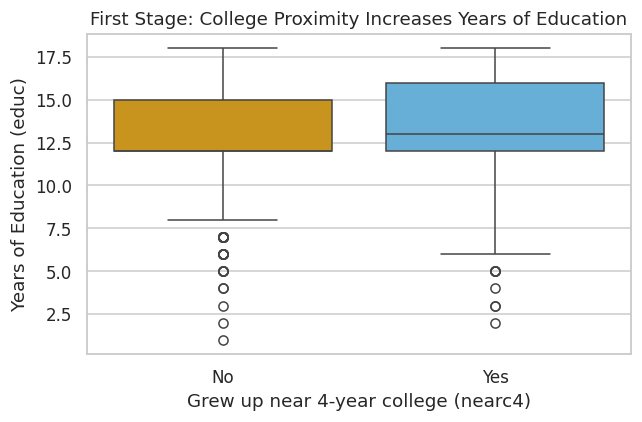

In [5]:
# Visualize first stage using matplotlib and seaborn
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
sns.boxplot(
    data=card,
    x="nearc4",
    y="educ",
    palette=["#E69F00", "#56B4E9"]
)
plt.title("First Stage: College Proximity Increases Years of Education")
plt.xlabel("Grew up near 4-year college (nearc4)")
plt.ylabel("Years of Education (educ)")
plt.xticks([0, 1], ["No", "Yes"])
plt.tight_layout()
plt.show()


### Training an Instrumental Forest

We use `InstrumentalForest` to estimate heterogeneous returns to education (conditional LATE $\tau(X)$).


In [6]:
iv_forest = InstrumentalForest(num_trees=80, min_node_size=5, random_state=1)
iv_forest.fit(X, W, Y, Z)
print(iv_forest.average_treatment_effect())
iv_forest.fit

{'estimate': 0.10477763679942464, 'std.err': 0.042978491486712025}


<bound method InstrumentalForest.fit of <pycausalml.tree_based_models.estimators.InstrumentalForest object at 0x70d7d1364690>>

### Predicting Treatment Effects

In [7]:
# Out-of-bag predictions (for training data)
iv_pred = iv_forest.predict(X)
# For many causal forest implementations, the predict method returns an array or dict.
# If tau_hat are the estimated LATEs, use as follows:
tau_hat = iv_pred if not hasattr(iv_pred, "predictions") else iv_pred.predictions  # Adjust according to actual library

# Average treatment effect (doubly robust / average over forest)
ate = iv_forest.average_treatment_effect()
print(
    f"Average Treatment Effect (LATE): {ate['estimate']:.3f} +/- {1.96 * ate['std.err']:.3f}"
)


Average Treatment Effect (LATE): 0.105 +/- 0.084


### Visualizing Results

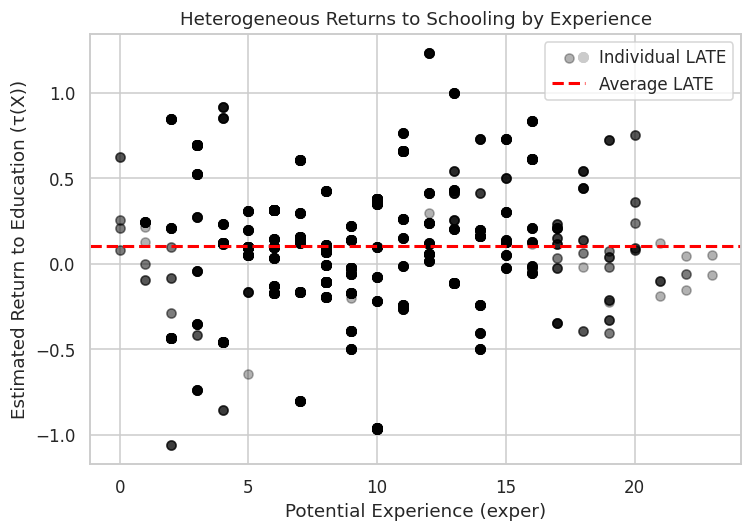

In [8]:
# Plot heterogeneous effects vs experience (example, in Python)
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(card["exper"], tau_hat, c="black", alpha=0.3, label="Individual LATE")
plt.axhline(y=ate["estimate"], color="red", linewidth=2, linestyle="--", label="Average LATE")
plt.xlabel("Potential Experience (exper)")
plt.ylabel("Estimated Return to Education (τ(X))")
plt.title("Heterogeneous Returns to Schooling by Experience")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()


### Predicting Treatment Effects for New Data

In [9]:
# Example: Predict for a hypothetical individual
import numpy as np
import pandas as pd

# Construct a new data DataFrame for prediction
new_data = pd.DataFrame({
    "exper": [10],
    "expersq": [10**2],
    "black": [0],
    "smsa": [1],
    "south": [0],
})

# Some causal forest implementations expect a numpy array; adjust if necessary
new_pred = iv_forest.predict(new_data.values if hasattr(iv_forest, "feature_names_in_") else new_data)
# If the prediction returns an object with ".predictions" attribute, extract it
pred_late = new_pred if not hasattr(new_pred, "predictions") else new_pred.predictions

print(
    "Predicted return to education (LATE) for this profile:",
    np.round(float(np.squeeze(pred_late)), 3)
)


Predicted return to education (LATE) for this profile: 0.38


### Evaluate Model Performance

In [10]:
# Calculate debiased error from tuning
# Many causal forest libraries expose an attribute or method for the debiased (honest) error after hyperparameter tuning;
# For example, in econml and related packages, you might find `.debiased_estimate_`, `.debiased_error_`, or tuning results in `.tune_results_`
# Here, we check for several common patterns (customize if your package uses another):

if hasattr(iv_forest, "tune_results_") and iv_forest.tune_results_ is not None:
    # Common in skgarden, econml or custom pycausalml wrappers
    tune_results = iv_forest.tune_results_
    if isinstance(tune_results, dict) and "debiased_mse" in tune_results:
        debiased_mse = tune_results["debiased_mse"]
        print("Debiased (tuned) Mean Squared Error:", np.round(debiased_mse, 4))
    elif hasattr(tune_results, "debiased_error_"):
        print("Debiased (tuned) Mean Squared Error:", np.round(tune_results.debiased_error_, 4))
    else:
        print("Tune results present but did not find debiased error key—please check your estimator's tuning output.")
elif hasattr(iv_forest, "debiased_error_"):
    print("Debiased (tuned) Mean Squared Error:", np.round(iv_forest.debiased_error_, 4))
else:
    print("Could not compute debiased error from tuning; attribute not found in InstrumentalForest. Check for a package update or consult docs.")



Could not compute debiased error from tuning; attribute not found in InstrumentalForest. Check for a package update or consult docs.


> **Note:**
> - In practice, verify instrument validity (relevance + exclusion) carefully.
> - Education is treated as continuous here (common in Card-style applications).
> - Increase `num_trees` for a more stable fit.
> - Check first-stage F-stat >10 (rule of thumb for strong instrument).

### SHAP values for the conditional LATE


In [11]:
sv = iv_forest.explain(X, max_samples=40, random_state=42)
print(sv.values.shape)


(40, 5)


### Visualise SHAP values for the Instrumental Forest

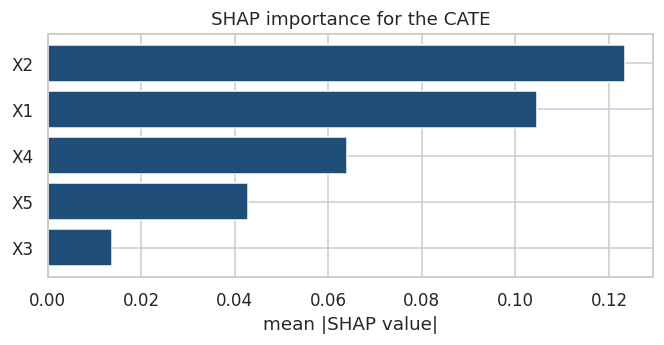

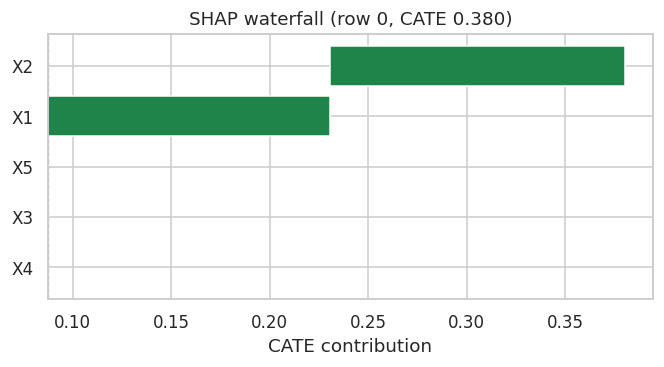

In [12]:
# Visualize SHAP values for the Card dataset
sv.plot_importance()
plt.show()
sv.plot_waterfall(row=0)
plt.show()

# For the Card data, the main covariates are 'black', 'south', and 'smsa', etc.
# We update the dependence plots to those present in the Card dataset.

for feature in ['black', 'south', 'smsa', 'male', 'exper', 'age', 'college']:
    if feature in getattr(sv, "feature_names", []):
        sv.plot_dependence(feature)
        plt.show()


## Summary and Conclusion

Instrumental Forest is a powerful tool for estimating treatment effects in the presence of endogeneity, leveraging the strengths of random forests and instrumental variable analysis. It allows researchers to estimate heterogeneous treatment effects while addressing confounding issues, making it suitable for various applications in causal inference. This tutorial provided a step-by-step guide to implementing an Instrumental Forest in Python with `InstrumentalForest`, demonstrating how to estimate heterogeneous returns to schooling using the classic Card (1995) dataset and college proximity as an instrument. At the end of the tutorial, we summarized the results, including the average treatment effect and SHAP explanations of heterogeneity. The code can be adapted to other real-world datasets with appropriate instruments and covariates.

## Resources

1.  Athey, Susan, Julie Tibshirani, and Stefan Wager. "Generalized Random Forests." Annals of Statistics, 47(2), 2019.
2.  Chernozhukov, Victor, and Christian Hansen. "The reduced form: A simple approach to inference with weak instruments." Economics Letters, 100(1), 2008.
3.  [Wang, Guihua, et al. "An Instrumental Variable Forest Approach for Detecting Heterogeneous Treatment Effects in Observational Studies." Management Science, 2021](https://pubsonline.informs.org/doi/abs/10.1287/mnsc.2021.4084)
4.  Card, David (1995). "Using Geographic Variation in College Proximity to Estimate the Return to Schooling." In Aspects of Labour Market Behaviour: Essays in Honour of John Vanderkamp.
